In [22]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve

In [ ]:
df = pd.read_csv('heart.csv')
df.head()

In [24]:
X = df.drop('target', axis=1)
y = df['target']

num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first'), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

best k: 9 roc-auc: 0.8874458874458875


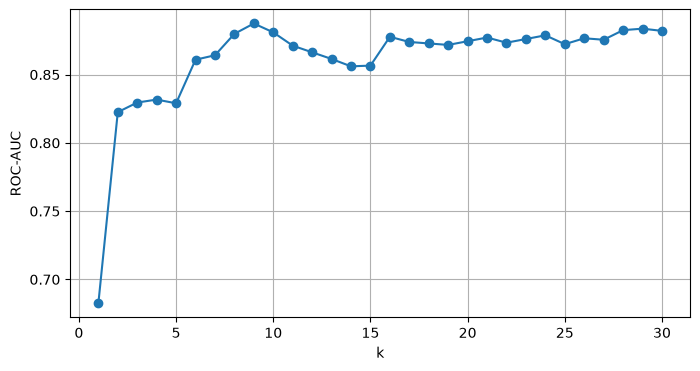

In [25]:
k_range = list(range(1, 31))
auc_scores = []

for k in k_range:
    pipe = Pipeline([
        ('prep', preprocessor),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    pipe.fit(X_train, y_train)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    auc_scores.append(roc_auc_score(y_test, y_prob))

best_k = k_range[auc_scores.index(max(auc_scores))]
print('best k:', best_k, 'roc-auc:', max(auc_scores))

plt.figure(figsize=(8, 4))
plt.plot(k_range, auc_scores, marker='o')
plt.xlabel('k')
plt.ylabel('ROC-AUC')
plt.grid()
plt.show()

KNN (k=9): Accuracy = 0.803, ROC-AUC = 0.887
SVM: Accuracy = 0.836, ROC-AUC = 0.886
Decision Tree: Accuracy = 0.721, ROC-AUC = 0.720
Random Forest: Accuracy = 0.787, ROC-AUC = 0.871


C:\Users\1\PycharmProjects\PythonProject\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


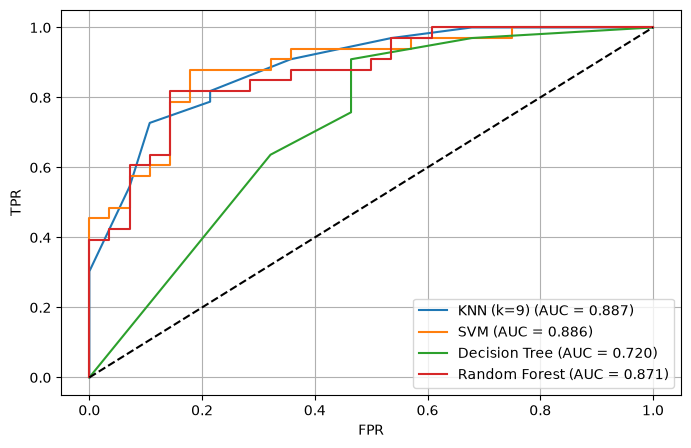

In [27]:
models = {
    f'KNN (k={best_k})': KNeighborsClassifier(n_neighbors=best_k),
    'SVM': SVC(probability=True, kernel='linear', C=0.1),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42)
}

plt.figure(figsize=(8, 5))

for name, model in models.items():
    pipe = Pipeline([
        ('prep', preprocessor),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    print(f'{name}: Accuracy = {acc:.3f}, ROC-AUC = {auc:.3f}')
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()
plt.grid()
plt.show()